# Active life: from the first dated work or position to the last

In [1]:
import json
import re
import sys
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../../../notebooks/notebooks_analysis')
from style import *

DB_PATH = '../../../data/cultura/cultura_database_V4.duckdb'  # read only
OUTPUT_PATH = Path('../../../data/enriched_parquets/individual_active_life.parquet')  # datamodel shape
SAVE = True  # True writes OUTPUT_PATH
POSITIONS_PATH = '../../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/position_held_P39_statements.json'  # raw P39 statements
KNOWN_PRECISIONS = ['day', 'month', 'year', 'decade']  # dates precise to the decade or better; coarser dates (century, millennium) are left out
DECADE_PRECISION = 8  # raw Wikidata precision: 8 decade, 9 year, 10 month, 11 day
MID_DECADE = 5  # a decade counts as its middle year
LIFETIME = 100  # years: the longest span of a single life
OCCUPATIONS = list(OCCUPATION_COLORS)  # the four occupational categories
ALL = 'All'  # no recorded occupation: the cohort of everyone
GROUPS = [*OCCUPATIONS, ALL]
MEASURES = ['start', 'end']
AGES = ['age_at_start', 'age_at_end']
AGE_RANGE = (10, 100)  # plausible ages at the start and the end of the active life, in years
LAST_BIRTH_YEAR = 1950  # born later: may still be active, neither learnt from nor imputed
MIN_COHORT = 10  # a smaller cohort takes the nearest century
CENTURY = 100  # years
TEST_SHARE = 0.2  # held-out share of the individuals with an active life
WITHIN = 10  # years between the imputed and the true year
GROUPINGS = {'overall': [], 'by century of birth': ['century'], 'by occupation': ['occupation'], 'by century of birth × occupation': ['century', 'occupation']}
STATISTICS = ['median', 'mean']  # the cohort's typical age
MODELS = {f'{statistic} {grouping}': (keys, statistic) for statistic in STATISTICS for grouping, keys in GROUPINGS.items()}
OVERALL = 'Overall'  # every individual, whatever the occupation
SPLIT_YEAR = 1500  # births before and after, in the second active-life figure
EXAMPLES = 12  # individuals with a birth and a death year shown with a predicted active life
MIN_SITELINKS = 20  # the examples are drawn among individuals with at least this many Wikipedia pages
SEED = 42

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Birth and death years from Wikidata only (no estimated date), precise to the year or the decade.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
people = con.sql('''
    WITH held AS (
        SELECT entity.qid AS qid, unnest(occupation).entity.qid AS occupation_qid, generate_subscripts(occupation, 1) AS position
        FROM individual
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation AS occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN occupation ON occupation.entity.qid = held.occupation_qid
        WHERE list_contains($occupations, occupation.meta_occupation)
        GROUP BY ALL
    ),
    main_occupation AS (
        SELECT qid, occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    ),
    dates AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS birth_year,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS death_year,
               coalesce(entity.label_en, entity.label_non_en) AS name,
               len(sitelink) AS sitelinks
        FROM individual
    )
    SELECT dates.qid, dates.name, dates.sitelinks,
           coalesce(main_occupation.occupation, $all) AS occupation,
           dates.birth_year, dates.death_year
    FROM dates
    LEFT JOIN main_occupation ON main_occupation.qid = dates.qid
''', params={'known': KNOWN_PRECISIONS, 'occupations': OCCUPATIONS, 'all': ALL}).pl()
death_caps = con.sql('''
    SELECT entity.qid AS qid,
           death_date.year AS death_cap,  -- Wikidata or estimated (01_age_at_death)
           CASE WHEN birth_date.source = 'estimated' THEN birth_date.year END AS estimated_birth_year  -- 01_age_at_death, Wikidata death only
    FROM individual_enriched
''').pl()
people = people.join(death_caps, on='qid', how='left')
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals')
people.sample(5, seed=SEED)

13,002,897 individuals


qid,name,sitelinks,occupation,birth_year,death_year,death_cap,estimated_birth_year
str,str,i64,str,i64,i64,i64,i64
"""Q4301588""","""Nikolay Monakhov""",4,"""Culture""",1875,1936,1936,null
"""Q2331013""","""Stanisław Maroński""",5,"""Discovery/Science""",1825,1907,1907,null
"""Q48954953""","""Владимиров, Константин Алексан…",1,"""Discovery/Science""",1860,1926,1926,null
"""Q2788195""","""George Morgan""",7,"""Sports/Games""",1993,null,null,null
"""Q58656684""","""Eva-Maria Nöthig""",0,"""Discovery/Science""",null,null,null,null


### Work dates
Inception (P571), else publication date (P577), precise to the year or the decade.

In [3]:
con.register('lifetime', people.select('qid', 'birth_year', 'death_year').to_arrow())
work_dates = con.sql('''
    WITH dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               list_contains($known, work.inception.precision) AS from_inception,
               CASE WHEN list_contains($known, work.inception.precision) THEN work.inception ELSE work.publication_date END AS date
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE list_contains($known, work.inception.precision) OR list_contains($known, work.publication_date.precision)
    )
    SELECT dated.qid, dated.work_qid,
           CASE WHEN dated.from_inception THEN 'inception' ELSE 'publication' END AS source,
           dated.date.year + CASE WHEN dated.date.precision = 'decade' THEN $mid_decade ELSE 0 END AS year,
           CASE WHEN dated.date.precision = 'decade' THEN 'decade' ELSE 'year' END AS precision,
           lifetime.birth_year, lifetime.death_year
    FROM dated
    JOIN lifetime ON lifetime.qid = dated.qid
''', params={'known': KNOWN_PRECISIONS, 'mid_decade': MID_DECADE}).pl()
con.close()
print(f'{work_dates.height:,} work dates for {work_dates["qid"].n_unique():,} individuals')
work_dates.sample(5, seed=SEED)

36,804,752 work dates for 2,773,370 individuals


qid,work_qid,source,year,precision,birth_year,death_year
str,str,str,i64,str,i64,i64
"""Q50638741""","""Q46446055""","""publication""",2005,"""year""",null,null
"""Q82105421""","""Q37690146""","""publication""",2013,"""year""",null,null
"""Q64864308""","""Q56906737""","""publication""",2018,"""year""",null,null
"""Q42655632""","""Q39376916""","""publication""",2013,"""year""",null,null
"""Q63668809""","""Q38965665""","""publication""",2014,"""year""",null,null


### Positions held
Start (P580) and end (P582) of position held (P39), precise to the year or the decade.

In [4]:
def dated_year(value):
    """The year of a start or end value precise to the decade or better, else None."""
    if not value or value['precision'] < DECADE_PRECISION:
        return None
    sign, digits = re.match(r'([+-]?)(\d+)-', value['time']).groups()
    year = -int(digits) if sign == '-' else int(digits)
    return year + (MID_DECADE if value['precision'] == DECADE_PRECISION else 0)


def precision(value):
    return None if not value or value['precision'] < DECADE_PRECISION else 'decade' if value['precision'] == DECADE_PRECISION else 'year'


raw = json.load(open(POSITIONS_PATH))
positions = pl.DataFrame(
    [{'qid': qid, 'position_qid': statement['target'],
      'start_year': dated_year(statement['start']), 'start_precision': precision(statement['start']),
      'end_year': dated_year(statement['end']), 'end_precision': precision(statement['end'])}
     for qid, statements in raw.items() for statement in statements if statement['rank'] != 'deprecated'],
    schema={'qid': pl.String, 'position_qid': pl.String, 'start_year': pl.Int64, 'start_precision': pl.String, 'end_year': pl.Int64, 'end_precision': pl.String},
)
del raw
print(f"{positions.height:,} position statements for {positions['qid'].n_unique():,} individuals")
positions = positions.join(people.select('qid', 'birth_year', 'death_year'), on='qid')
print(f"{positions.height:,} statements for {positions['qid'].n_unique():,} individuals of the database")
positions.sample(5, seed=SEED)

1,947,131 position statements for 979,289 individuals


1,947,131 statements for 979,289 individuals of the database


qid,position_qid,start_year,start_precision,end_year,end_precision,birth_year,death_year
str,str,i64,str,i64,str,i64,i64
"""Q65570249""","""Q65462718""",2026,"""year""",null,null,1957,null
"""Q50806480""","""Q589298""",2013,"""year""",null,null,1973,null
"""Q3309832""","""Q65491440""",2014,"""year""",2020,"""year""",1956,null
"""Q111841667""","""Q19953712""",null,null,null,null,null,null
"""Q54666345""","""Q137459138""",2018,"""year""",null,null,1955,null


## Cleaning
### Work dates (as in 02_works_periods)
1. Individuals without birth or death whose dated works carry only publication dates are excluded: a publication date may be a much later edition.
2. A work date must fall inside the lifetime: birth to death, or within 100 years of a single birth or death.
3. For individuals without birth or death, a publication date more than 100 years from their earliest inception is removed.
4. Individuals without birth or death whose inception dates alone span more than 100 years lose all their work dates.

In [5]:
has_lifetime = pl.col('birth_year').is_not_null() | pl.col('death_year').is_not_null()
inception_years = pl.col('year').filter(pl.col('source') == 'inception')
lower = pl.coalesce('birth_year', pl.col('death_year') - LIFETIME)
upper = pl.coalesce('death_year', pl.col('birth_year') + LIFETIME)
WORK_RULES = {
    '1. publication dates only, no birth or death': ~has_lifetime & inception_years.min().over('qid').is_null(),
    '2. outside the lifetime': ~pl.col('year').is_between(lower, upper),
    '3. publication over 100 years from the earliest inception': ~has_lifetime & (pl.col('source') == 'publication') & ((pl.col('year') - inception_years.min().over('qid')).abs() > LIFETIME),
    '4. inceptions spanning over 100 years': ~has_lifetime & ((inception_years.max() - inception_years.min()).over('qid') > LIFETIME),
}


def apply_rules(frame, rules, unit):
    """Apply the rules one after the other, logging the rows and the individuals left after each."""
    log = [{'step': 'start', unit: frame.height, 'individuals': frame['qid'].n_unique()}]
    for step, dropped in rules.items():
        frame = frame.filter(~dropped.fill_null(False))
        log.append({'step': step, unit: frame.height, 'individuals': frame['qid'].n_unique()})
    display(pl.DataFrame(log))
    return frame


kept_works = apply_rules(work_dates, WORK_RULES, 'work dates')

step,work dates,individuals
str,i64,i64
"""start""",36804752,2773370
"""1. publication dates only, no …",9637863,599887
"""2. outside the lifetime""",9479750,584832
"""3. publication over 100 years …",9478965,584832
"""4. inceptions spanning over 10…",9478728,584786


### Positions held
1. A position needs a start or an end (one is enough).
2. The end cannot come before the start.
3. Each start and end is then a position date, which must fall inside the lifetime (as for the works).
4. Individuals without birth or death whose position dates span more than 100 years lose all of them.

In [6]:
POSITION_RULES = {
    '1. no start and no end': pl.col('start_year').is_null() & pl.col('end_year').is_null(),
    '2. end before start': pl.col('end_year') < pl.col('start_year'),
}
DATE_RULES = {
    '3. outside the lifetime': ~pl.col('year').is_between(lower, upper),
    '4. position dates spanning over 100 years': ~has_lifetime & ((pl.col('year').max() - pl.col('year').min()).over('qid') > LIFETIME),
}
kept_positions = apply_rules(positions, POSITION_RULES, 'positions')
position_dates = pl.concat([
    kept_positions.select('qid', 'birth_year', 'death_year', pl.lit(f'position {end}').alias('kind'), pl.col(f'{end}_year').alias('year'), pl.col(f'{end}_precision').alias('precision'))
    for end in ('start', 'end')
]).drop_nulls('year')
kept_position_dates = apply_rules(position_dates, DATE_RULES, 'position dates')

step,positions,individuals
str,i64,i64
"""start""",1947131,979289
"""1. no start and no end""",1276638,574868
"""2. end before start""",1276296,574753


step,position dates,individuals
str,i64,i64
"""start""",2258908,574753
"""3. outside the lifetime""",2254925,574265
"""4. position dates spanning ove…",2254541,574224


## Active life
From the earliest dated work or position to the latest.

In [7]:
events = pl.concat([
    kept_works.select('qid', 'year', 'precision', pl.lit('work').alias('kind')),
    kept_position_dates.select('qid', 'year', 'precision', 'kind'),
])
active = (
    events.group_by('qid')
    .agg(
        pl.col('year').min().alias('start_year'),
        pl.col('year').max().alias('end_year'),
        pl.col('kind').sort_by('year', 'kind').first().alias('start_source'),
        pl.col('kind').sort_by('year', 'kind').last().alias('end_source'),
        pl.col('precision').sort_by('year', pl.col('precision') == 'decade').first().alias('start_precision'),
        pl.col('precision').sort_by('year', pl.col('precision') == 'year').last().alias('end_precision'),
        (pl.col('kind') == 'work').any().alias('has_work'),
        (pl.col('kind') != 'work').any().alias('has_position'),
    )
    .join(people, on='qid')
)
print(f'{active.height:,} individuals with dated works or positions')
active = active.filter(has_lifetime | (pl.col('end_year') - pl.col('start_year') <= LIFETIME))
print(f'{active.height:,} after dropping those with no birth or death spanning over {LIFETIME} years')
active = active.with_columns(
    (pl.col('start_year') - pl.col('birth_year')).alias('age_at_start'),
    (pl.col('end_year') - pl.col('birth_year')).alias('age_at_end'),
    (pl.col('birth_year') // CENTURY * CENTURY).alias('century'),
)
assert active['qid'].is_unique().all() and (active['start_year'] <= active['end_year']).all()
active.sample(5, seed=SEED)

1,133,997 individuals with dated works or positions
1,133,994 after dropping those with no birth or death spanning over 100 years


qid,start_year,end_year,start_source,end_source,start_precision,end_precision,has_work,has_position,name,sitelinks,occupation,birth_year,death_year,death_cap,estimated_birth_year,age_at_start,age_at_end,century
str,i64,i64,str,str,str,str,bool,bool,str,i64,str,i64,i64,i64,i64,i64,i64,i64
"""Q60656616""",1997,2013,"""work""","""work""","""year""","""year""",true,false,"""Mathias Wargon""",1,"""Discovery/Science""",1966,null,null,null,31,47,1900
"""Q118426558""",1871,1871,"""position start""","""position start""","""year""","""year""",false,true,"""Jean Veissière""",0,"""All""",null,null,null,null,null,null,null
"""Q55415715""",1929,2007,"""work""","""work""","""year""","""year""",true,false,"""Valerie Maxfield""",2,"""Discovery/Science""",null,null,null,null,null,null,null
"""Q56947846""",2017,2020,"""work""","""work""","""year""","""year""",true,false,"""Julia Pohl""",0,"""Discovery/Science""",1986,null,null,null,31,34,1900
"""Q98925655""",1921,1927,"""work""","""work""","""year""","""year""",true,false,"""Pengnian Ren""",3,"""Culture""",1894,1968,1968,null,27,33,1800


## Age at the start and the end of the active life
Individuals born up to 1950 whose active life starts and ends between ages 10 and 100.

In [8]:
lives = active.filter(
    (pl.col('birth_year') <= LAST_BIRTH_YEAR)
    & pl.col('age_at_start').is_between(*AGE_RANGE)
    & pl.col('age_at_end').is_between(*AGE_RANGE)
)
print(f'{lives.height:,} of {active.height:,} active lives')
lives = lives.filter(pl.col('start_year') < pl.col('end_year'))
print(f'{lives.height:,} with the start and the end in different years')

555,912 of 1,133,994 active lives
404,674 with the start and the end in different years


### Table 7: Sources of the observed active lives

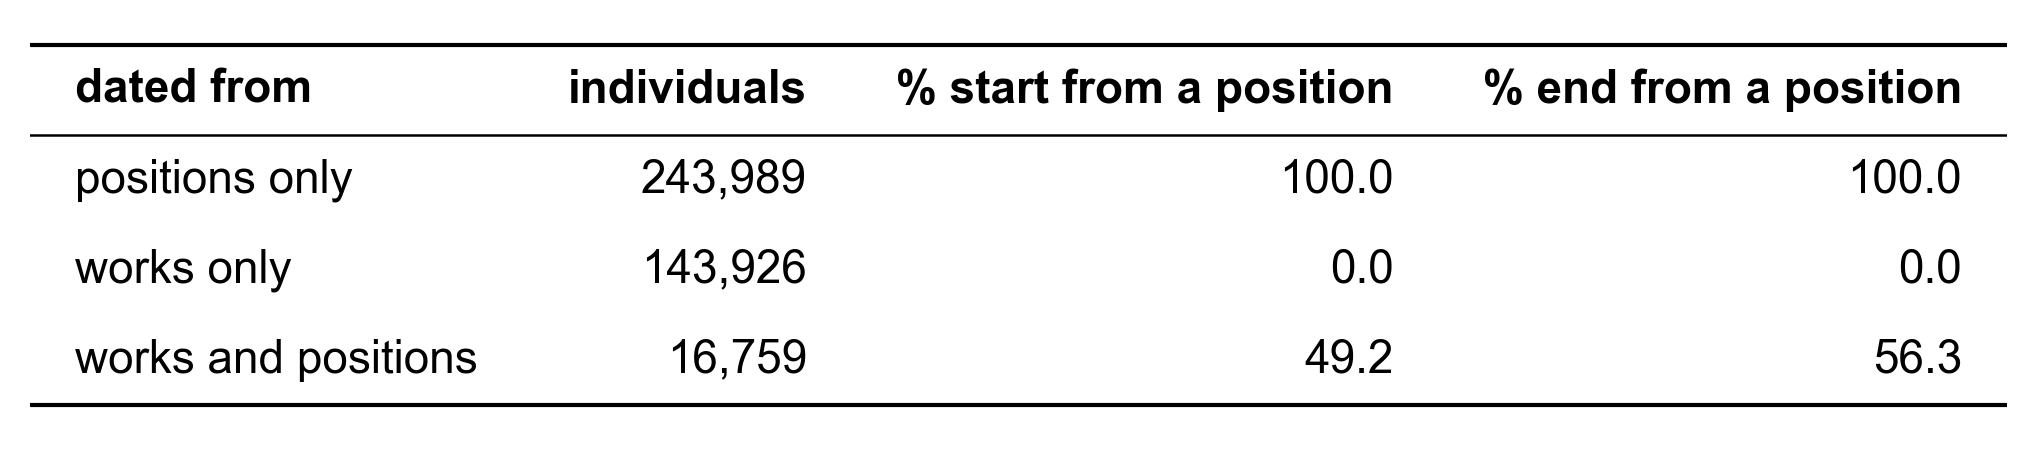

In [9]:
made_of = lives.with_columns(
    pl.when(pl.col('has_work') & pl.col('has_position')).then(pl.lit('works and positions'))
    .when(pl.col('has_work')).then(pl.lit('works only'))
    .otherwise(pl.lit('positions only')).alias('dated from')
).group_by('dated from').agg(
    pl.len().alias('individuals'),
    (100 * (pl.col('start_source') != 'work').mean()).alias('% start from a position'),
    (100 * (pl.col('end_source') != 'work').mean()).alias('% end from a position'),
).sort('individuals', descending=True)
assert made_of['individuals'].sum() == lives.height
show_table(made_of, decimals=1)

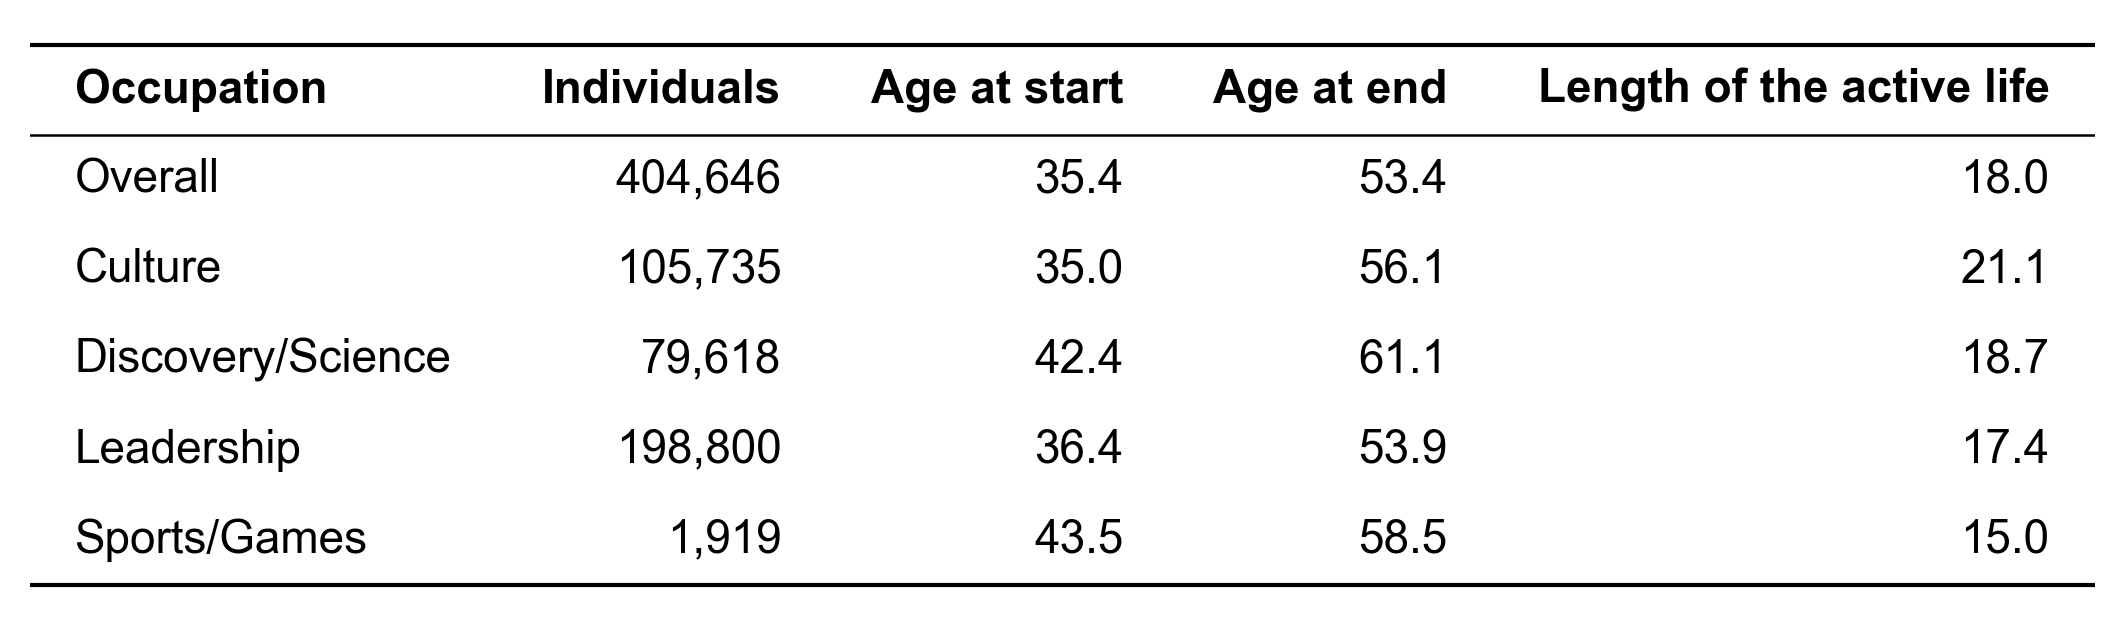

In [10]:
def century_average(frame, by, statistic='median'):
    """Median (or mean) ages in every century of birth with at least MIN_COHORT individuals, averaged over those centuries."""
    return (
        frame.group_by(*by, 'century').agg(pl.len().alias('individuals'), getattr(pl.col(AGES), statistic)())
        .filter(pl.col('individuals') >= MIN_COHORT)
        .group_by(by).agg(pl.col('individuals').sum(), pl.len().alias('centuries'), pl.col(AGES).mean())
    )


def spans(frame):
    """Century-averaged ages at the start and the end: overall (every individual) and for each of the four occupations."""
    return pl.concat([
        century_average(frame.with_columns(pl.lit(OVERALL).alias('occupation')), ['occupation']),
        century_average(frame.filter(pl.col('occupation') != ALL), ['occupation']),
    ]).sort(pl.col('occupation').replace_strict([OVERALL, *OCCUPATIONS], list(range(len(OCCUPATIONS) + 1))))


TABLE_HEADERS = {'occupation': 'Occupation', 'individuals': 'Individuals', 'age_at_start': 'Age at start', 'age_at_end': 'Age at end'}
show_table(
    spans(lives).with_columns((pl.col('age_at_end') - pl.col('age_at_start')).alias('Length of the active life'))
    .drop('centuries').rename(TABLE_HEADERS),
    decimals=1,
)

In [ ]:
ROW_ORDER = [OVERALL, *OCCUPATIONS]
ROW_COLORS = {OVERALL: MAIN_LINE_COLOR, **OCCUPATION_COLORS}


def draw_span(ax, y, row, color, side=1, hollow=False, show_n=False):
    start, end = row['age_at_start'], row['age_at_end']
    ax.plot([start, end], [y, y], color=color, linewidth=8, solid_capstyle='round', alpha=0.25 if hollow else 0.5)
    ax.plot([start, end], [y, y], 'o', color=color, markersize=10, markeredgewidth=2, markerfacecolor='white' if hollow else color)
    ax.annotate(f'{start:.0f}', (start, y), xytext=(-12, 0), textcoords='offset points', ha='right', va='center')
    ax.annotate(f'{end:.0f}', (end, y), xytext=(12, 0), textcoords='offset points', ha='left', va='center')
    length = f"{end - start:.1f} years" + (f" (n = {row['individuals']:,})" if show_n else '')
    ax.annotate(length, ((start + end) / 2, y), xytext=(0, 10 * side), textcoords='offset points', ha='center',
                va='bottom' if side > 0 else 'top', color=MUTED_TEXT, fontsize=POINT_LABEL_FONTSIZE)


def finish(ax, labels):
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels[::-1])
    ax.set_ylim(-0.7, len(labels) - 0.3)
    ax.set_xlim(20, 75)
    ax.set_xlabel('Age (years)')
    ax.grid(axis='y', visible=False)
    plt.tight_layout()
    plt.show()


everyone = {row['occupation']: row for row in spans(lives).iter_rows(named=True)}
rows = [group for group in ROW_ORDER if group in everyone]

### Figure 3: Age at the start and the end of the active life, born before and after 1500

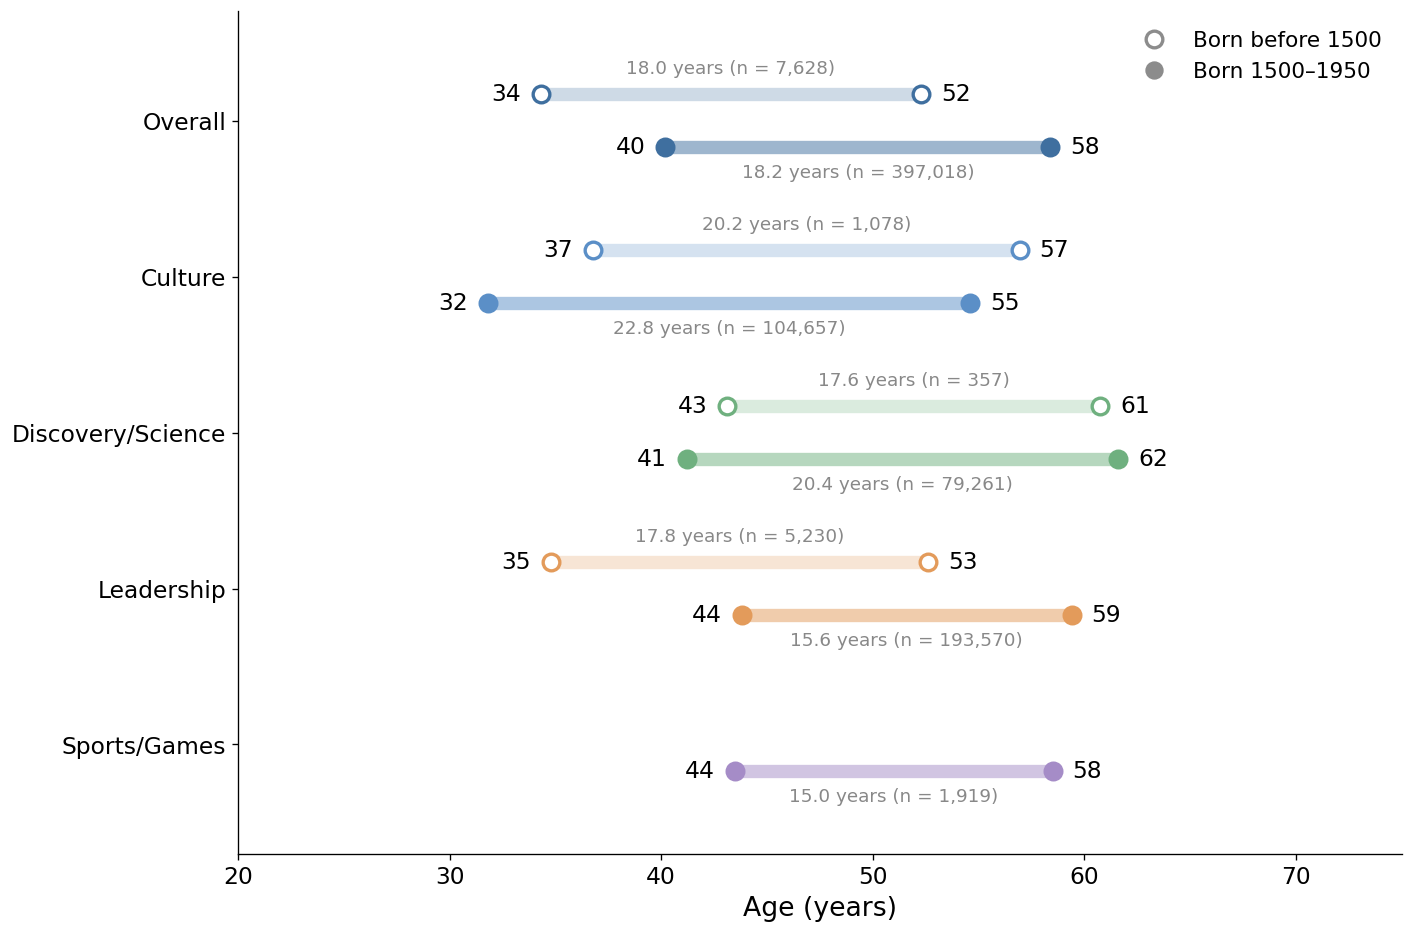

In [12]:
before = {row['occupation']: row for row in spans(lives.filter(pl.col('birth_year') < SPLIT_YEAR)).iter_rows(named=True)}
after = {row['occupation']: row for row in spans(lives.filter(pl.col('birth_year') >= SPLIT_YEAR)).iter_rows(named=True)}
fig, ax = plt.subplots(figsize=(12, 8))
for i, group in enumerate(rows):
    y = len(rows) - 1 - i
    if group in before:
        draw_span(ax, y + 0.17, before[group], ROW_COLORS[group], side=1, hollow=True, show_n=True)
    if group in after:
        draw_span(ax, y - 0.17, after[group], ROW_COLORS[group], side=-1, show_n=True)
ax.plot([], [], 'o', color=GREY, markerfacecolor='white', markeredgewidth=2, markersize=10, label=f'Born before {SPLIT_YEAR}')
ax.plot([], [], 'o', color=GREY, markersize=10, label=f'Born {SPLIT_YEAR}–{LAST_BIRTH_YEAR}')
ax.legend(loc='upper right')
finish(ax, rows)

## Models
Birth year + the median (or mean) age at the start or the end of the active life of the individual's cohort.

In [13]:
first_century = people['birth_year'].min() // CENTURY * CENTURY
grid = pl.DataFrame({'century': range(first_century, LAST_BIRTH_YEAR // CENTURY * CENTURY + 1, CENTURY)}).join(pl.DataFrame({'occupation': GROUPS}), how='cross')


def cohort_table(lives, measure, model):
    """Median (or mean) age at the start or the end of the model's cohort, for every century of birth and occupation."""
    keys, statistic = MODELS[model]
    if 'occupation' in keys:
        lives = pl.concat([lives.filter(pl.col('occupation') != ALL), lives.with_columns(pl.lit(ALL).alias('occupation'))])
    if 'century' not in keys:
        everyone = lives.with_columns(pl.lit(OVERALL).alias('everyone'))
        cohorts = century_average(everyone, keys or ['everyone'], statistic).select(*keys, pl.col('individuals').alias('cohort_individuals'), pl.col(f'age_at_{measure}').alias('age'))
        table = (grid.join(cohorts, on=keys) if keys else grid.join(cohorts, how='cross')).with_columns(pl.col('century').alias('cohort_century'))
    else:
        cohorts = (
            lives.group_by(keys).agg(pl.len().alias('cohort_individuals'), getattr(pl.col(f'age_at_{measure}'), statistic)().alias('age'))
            .filter(pl.col('cohort_individuals') >= MIN_COHORT).rename({'century': 'cohort_century'})
        )
        others = [key for key in keys if key != 'century']
        table = (
            (grid.join(cohorts, on=others) if others else grid.join(cohorts, how='cross'))
            .sort((pl.col('cohort_century') - pl.col('century')).abs(), 'cohort_century', descending=[False, True])
            .group_by('occupation', 'century', maintain_order=True).first()
        )
    assert table.height == grid.height
    return table


def impute(targets, tables):
    """Start and end = birth year + the cohort's median age, the end no later than the death and the start no later than the end."""
    imputed = targets.select('qid', 'name', 'occupation', 'birth_year', 'death_year', 'death_cap', *[c for c in ('start_year', 'end_year') if c in targets.columns]).with_columns(
        (pl.col('birth_year') // CENTURY * CENTURY).clip(grid['century'].min(), grid['century'].max()).alias('century')
    )
    for measure, table in tables.items():
        imputed = imputed.join(
            table.select('occupation', 'century', *[pl.col(c).alias(f'{measure}_{c}') for c in ('cohort_century', 'cohort_individuals', 'age')]),
            on=['occupation', 'century'], how='left',
        ).with_columns((pl.col('birth_year') + pl.col(f'{measure}_age').round()).cast(pl.Int64).alias(f'{measure}_from_cohort'))
    imputed = imputed.with_columns(pl.min_horizontal('end_from_cohort', 'death_cap').alias('imputed_end_year'))
    imputed = imputed.with_columns(pl.min_horizontal('start_from_cohort', 'imputed_end_year').alias('imputed_start_year'))
    assert imputed.height == targets.height and imputed['imputed_start_year'].null_count() == imputed['imputed_end_year'].null_count() == 0
    return imputed

## Test on a held-out 20%

In [14]:
test = lives.sort('qid').sample(fraction=TEST_SHARE, shuffle=True, seed=SEED)
train = lives.join(test, on='qid', how='anti')
assert train.height + test.height == lives.height
print(f'train: {train.height:,}, test: {test.height:,}')

scores = []
for model in MODELS:
    imputed_test = impute(test, {measure: cohort_table(train, measure, model) for measure in MEASURES})
    row = {'model': model}
    for measure in MEASURES:
        per_century = (
            imputed_test.with_columns((pl.col(f'imputed_{measure}_year') - pl.col(f'{measure}_year')).abs().alias('error'))
            .group_by('century')
            .agg(pl.len().alias('individuals'), pl.col('error').mean().alias('error'), (100 * (pl.col('error') <= WITHIN).mean()).alias('within'))
            .filter(pl.col('individuals') >= MIN_COHORT)
        )
        row[f'{measure}: mean absolute error'] = per_century['error'].mean()
        row[f'{measure}: % within {WITHIN} years'] = per_century['within'].mean()
    scores.append(row)
scores = pl.DataFrame(scores)
median_scores = scores.filter(pl.col('model').str.starts_with('median'))
BEST = {measure: median_scores.sort(f'{measure}: % within {WITHIN} years', descending=True)['model'][0] for measure in MEASURES}
print(f"best model, start of the active life: {BEST['start']}; end: {BEST['end']}")

train: 323,740, test: 80,934


best model, start of the active life: median by century of birth × occupation; end: median by century of birth × occupation


### Table 8: Accuracy of the four models on a held-out 20%

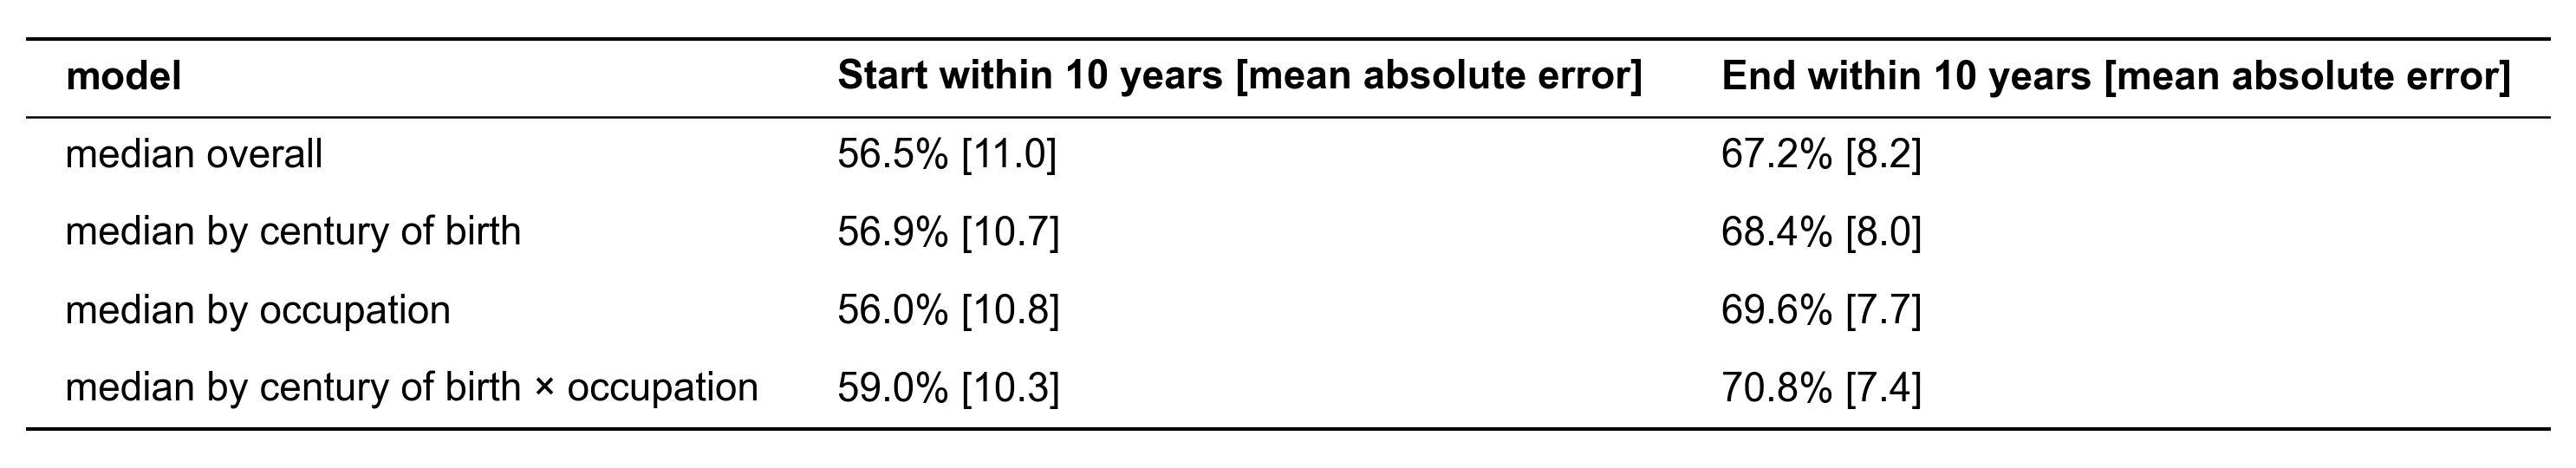

In [15]:
show_table(median_scores.select('model', *[
    pl.format('{}% [{}]', pl.col(f'{measure}: % within {WITHIN} years').round(1), pl.col(f'{measure}: mean absolute error').round(1))
    .alias(f'{measure.capitalize()} within {WITHIN} years [mean absolute error]')
    for measure in MEASURES
]))

In [ ]:
tables = {measure: cohort_table(lives, measure, BEST[measure]) for measure in MEASURES}
with_active_life = active.filter(pl.col('start_year') < pl.col('end_year'))

## Imputation for everyone without an active life

In [17]:
single_year = active.filter(pl.col('start_year') == pl.col('end_year')).select('qid', pl.col('start_year').alias('single_year'))
targets = (
    people.join(with_active_life, on='qid', how='anti')
    .join(single_year, on='qid', how='left')
    .with_columns(pl.col('birth_year').is_null().alias('estimated_birth'), pl.coalesce('birth_year', 'estimated_birth_year').alias('birth_year'))
    .filter(pl.col('birth_year') <= LAST_BIRTH_YEAR)
)
imputed = impute(targets, tables).join(targets.select('qid', 'estimated_birth', 'single_year'), on='qid')
print(f'{imputed.height:,} individuals imputed ({imputed["estimated_birth"].sum():,} from an estimated birth)')

4,100,202 individuals imputed (275,188 from an estimated birth)


## Save

In [19]:
sys.path.insert(0, '../../1-datamodels')
sys.path.insert(0, '../../3-raw_to_db/helpers')
import datamodel_in_duckdb as D
from pydantic_to_duckdb_schema import duck_type

DATE_TYPE = duck_type(D.IndividualDate)
INPUTS = ['Individual.work', 'Work.inception', 'Work.publication_date', 'Individual.position_held', 'Individual.birth_date', 'Individual.death_date', 'IndividualEnriched.birth_date', 'IndividualEnriched.death_date', 'Occupation.meta_occupation']
OBSERVED_RULE = (
    f'From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, '
    f'precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within {LIFETIME} years of a single birth or death), cleaned as in 03_b_active_life.'
)


def estimated_rule(measure):
    keys, statistic = MODELS[BEST[measure]]
    group = pl.when(pl.col('occupation') == ALL).then(pl.lit('individuals')).otherwise(pl.col('occupation') + ' individuals') if 'occupation' in keys else pl.lit('individuals')
    born = pl.format(' born in {}–{}', f'{measure}_cohort_century', pl.col(f'{measure}_cohort_century') + CENTURY - 1) if 'century' in keys else pl.lit('')
    cap = 'the death year' if measure == 'end' else 'the estimated end'
    capped = pl.when(pl.col(f'imputed_{measure}_year') != pl.col(f'{measure}_from_cohort')).then(pl.lit(f', capped at {cap}')).otherwise(pl.lit(''))
    birth = pl.when(pl.col('estimated_birth')).then(pl.lit('the birth year estimated from the age at death')).otherwise(pl.lit('the Wikidata birth year'))
    return pl.format(f'Estimated: {{}} + {{}} years, the {statistic} age at the {measure} of the active life of the {{}} {{}}{{}} ({BEST[measure]}){{}}.',
                     birth, pl.col(f'{measure}_age').round(1), f'{measure}_cohort_individuals', group, born, capped)


def cohort(measure):
    keys, _ = MODELS[BEST[measure]]
    return pl.struct(
        (pl.when(pl.col('occupation') != ALL).then('occupation') if 'occupation' in keys else pl.lit(None, pl.String)).alias('occupation'),
        (pl.col(f'{measure}_cohort_century') if 'century' in keys else pl.lit(None, pl.Int64)).alias('century'),
        pl.col(f'{measure}_cohort_individuals').cast(pl.Int64).alias('individuals'),
        pl.col(f'{measure}_age').cast(pl.Float64).alias('age'),
    ).alias(f'{measure}_cohort')


observed = active.join(imputed, on='qid', how='anti')
active_lives = pl.concat([
    observed.select('qid', 'start_year', 'end_year', 'start_precision', 'end_precision', pl.lit('dated works and positions').alias('source'),
                    pl.lit(OBSERVED_RULE).alias('start_rule'), pl.lit(OBSERVED_RULE).alias('end_rule')),
    imputed.select('qid', pl.col('imputed_start_year').alias('start_year'), pl.col('imputed_end_year').alias('end_year'), pl.lit('estimated').alias('source'),
                   estimated_rule('start').alias('start_rule'), estimated_rule('end').alias('end_rule'), cohort('start'), cohort('end')),
], how='diagonal')
assert active_lives['qid'].is_unique().all() and (active_lives['start_year'] <= active_lives['end_year']).all()


def active_life_date(measure):
    provenance = f"{{'raw': [], 'inputs': $inputs, 'rule': active_lives.{measure}_rule, 'ai_answer': NULL, 'retrieved_on': NULL}}"
    return f"""CAST({{'iso': NULL, 'year': active_lives.{measure}_year, 'precision': coalesce(active_lives.{measure}_precision, 'year'),
        'field_provenance': MAP {{'year': {provenance}, 'precision': {provenance}}}, 'source': active_lives.source, 'cohort': active_lives.{measure}_cohort, 'coarse_label': NULL::VARCHAR}} AS {DATE_TYPE}) AS {measure}_of_active_life"""


ACTIVE_LIVES = f"""
    SELECT qid, {active_life_date('start')}, {active_life_date('end')}
    FROM active_lives
"""
local = duckdb.connect()
local.register('active_lives', active_lives.to_arrow())
local.sql(f"SELECT * FROM ({ACTIVE_LIVES}) USING SAMPLE 4 ROWS (reservoir, {SEED})", params={'inputs': INPUTS}).pl()

qid,start_of_active_life,end_of_active_life
str,struct[7],struct[7]
"""Q57302""","{null,1839,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}, {""precision"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}],""dated works and positions"",null,null}","{null,1905,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}, {""precision"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}],""dated works and positions"",null,null}"
"""Q11075438""","{null,1997,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}, {""precision"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}],""dated works and positions"",null,null}","{null,2022,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}, {""precision"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}],""dated works and positions"",null,null}"
"""Q3506475""","{null,1977,""year""

In [20]:
if SAVE:
    OUTPUT_PATH.parent.mkdir(exist_ok=True)
    local.execute(f"COPY ({ACTIVE_LIVES} ORDER BY qid) TO '{OUTPUT_PATH}' (FORMAT parquet)", {'inputs': INPUTS})
    saved = local.sql(f"SELECT count(*) AS individuals, count(*) FILTER (start_of_active_life.source = 'dated works and positions') AS from_dated_works_and_positions, count(*) FILTER (start_of_active_life.source = 'estimated') AS estimated FROM '{OUTPUT_PATH}'").pl()
    assert saved['from_dated_works_and_positions'][0] == observed.height and saved['estimated'][0] == imputed.height
    display(saved)

individuals,from_dated_works_and_positions,estimated
i64,i64,i64
5072350,972148,4100202
